# Task 1

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, root_mean_squared_error
from sklearn.decomposition import TruncatedSVD


In [22]:
#Load datasets
digits = load_digits()
X = digits.data
y = digits.target

#Split dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print(f"X shape: {X.shape}")
print(f"Pixel range: {X.min()} to {X.max()}")
print(f"Classes: {np.unique(y).tolist()}")
print(f"Training shape: {X_train.shape}, Test shape: {X_test.shape}")

X shape: (1797, 64)
Pixel range: 0.0 to 16.0
Classes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Training shape: (1437, 64), Test shape: (360, 64)


# Task 2

In [9]:
knn_base = KNeighborsClassifier(n_neighbors=5)
knn_base.fit(X_train, y_train)

y_pred_base = knn_base.predict(X_test)
base_acc = accuracy_score(y_test, y_pred_base)
print(f"Baseline Test Accuracy: {base_acc:.4f}")

Baseline Test Accuracy: 0.9833


# Task 3

In [12]:
svd_3 = TruncatedSVD(n_components=3, n_iter=10, random_state=42)
Z_train = svd_3.fit_transform(X_train)
Z_test = svd_3.transform(X_test)

print(f"Z_train shape: {Z_train.shape}")
print(f"Z_test shape: {Z_test.shape}")
print(f"Component shape: {svd_3.components_.shape}")
print(f"Singular values: {svd_3.singular_values_}")
print(f"First five reduce training rows:\n{Z_train[:5]}")

Z_train_manual = X_train @ svd_3.components_.T
verification_diff = np.allclose(Z_train, Z_train_manual)
print(f"Verification Z_train == X_train @ components_.T: {verification_diff}")

Z_train shape: (1437, 3)
Z_test shape: (360, 3)
Component shape: (3, 64)
Singular values: [1965.91430362  504.14849431  486.24709673]
First five reduce training rows:
[[ 58.38645887 -12.14745105  -3.91423699]
 [ 53.59671905   4.98516153 -16.30752833]
 [ 52.62131118   2.01111484  11.21669637]
 [ 45.58572639   1.62762611  22.57867921]
 [ 40.32792542  -1.84218886   5.59060146]]
Verification Z_train == X_train @ components_.T: True


# Task 4

In [14]:
#Train classifier on Z_train
knn_3 = KNeighborsClassifier(n_neighbors=5)
knn_3.fit(Z_train, y_train)

#Predict on Z_test
y_pred_3 = knn_3.predict(Z_test)
acc_3 = accuracy_score(y_test, y_pred_3)

print(f"Test Accuracy: {acc_3:.4f}")
print(f"First 10 Predicted labels: {y_pred_3[:10]}")
print(f"First 10 Actual labels: {y_test[:10]}")

#Confusion matrix with classes order 0 to 9
cm_3 = confusion_matrix(y_test, y_pred_3, labels=range(10))
print("Confusion matrix: \n", cm_3)

Test Accuracy: 0.6528
First 10 Predicted labels: [5 8 1 4 4 2 6 2 6 7]
First 10 Actual labels: [5 2 8 1 7 2 6 2 6 5]
Confusion matrix: 
 [[31  0  0  0  0  0  5  0  0  0]
 [ 1 18  1  0  3  5  0  5  3  0]
 [ 0  0 27  2  0  2  0  0  3  1]
 [ 0  0  7 22  0  0  0  1  0  7]
 [ 0  1  0  0 32  1  2  0  0  0]
 [ 2  5  5  0  0 11  0  2 10  2]
 [ 0  0  0  0  3  0 33  0  0  0]
 [ 0  5  0  0  1  2  0 28  0  0]
 [ 1  4  2  0  0  8  0  5 14  1]
 [ 0  1  4  2  0  6  0  4  0 19]]


# Task 5

In [19]:
k_values = [3, 16, 32]
total_X_energy = np.sum(X_train**2)

print(f"{'Featres':<10} | {'Test Accuracy':<15} | {'Energy %':<10} | {'Train RMSE':<15} | {'Train Bytes'}")
print("-" * 75)
print(f"{64:<10} | {base_acc:<15.4f} | {'N/A':<10} | {'N/A':<15} | {X_train.nbytes}")

for k in k_values:
    svd = TruncatedSVD(n_components=k, n_iter=10, random_state=42)
    Z_train_k = svd.fit_transform(X_train)
    Z_test_k = svd.transform(X_test)
    
    knn_k = KNeighborsClassifier(n_neighbors=5)
    knn_k.fit(Z_train_k, y_train)
    acc_k = accuracy_score(y_test, knn_k.predict(Z_test_k))
    
    energy_pct = 100 * np.sum(Z_train_k**2) / total_X_energy
    X_train_reconstructed = svd.inverse_transform(Z_train_k)
    rmse = root_mean_squared_error(X_train, X_train_reconstructed)
    
    print(f"{k:<10} | {acc_k:<15.4f} | {energy_pct:<10.2f} | {rmse:<15.4f} | {Z_train_k.nbytes}")

Featres    | Test Accuracy   | Energy %   | Train RMSE      | Train Bytes
---------------------------------------------------------------------------
64         | 0.9833          | N/A        | N/A             | 735744
3          | 0.6528          | 78.65      | 3.0762          | 34488
16         | 0.9861          | 95.28      | 1.4993          | 183936
32         | 0.9806          | 98.96      | 0.7071          | 367872


# Task 6

Input shape: (1, 64)
Reduced shape: (1, 3)
Prediction: 5
True label: 5


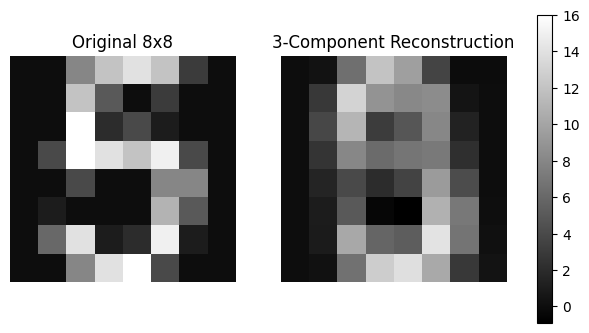

In [20]:
new_obs_X = X_test[0:1]
true_label = y_test[0]

new_obs_Z = svd_3.transform(new_obs_X)
predicted_label = knn_3.predict(new_obs_Z)[0]

print(f"Input shape: {new_obs_X.shape}")
print(f"Reduced shape: {new_obs_Z.shape}")
print(f"Prediction: {predicted_label}")
print(f"True label: {true_label}")

reconstructed_X = svd_3.inverse_transform(new_obs_Z)

fig, axes = plt.subplots(1, 2, figsize=(8,4))
vmax = max(new_obs_X.max(), reconstructed_X.max())
vmin = min(new_obs_X.min(), reconstructed_X.min())

ax1 = axes[0]
im1 = ax1.imshow(new_obs_X.reshape(8,8), cmap='gray', vmin=vmin, vmax=vmax)
ax1.set_title("Original 8x8")
ax1.axis('off')

ax2 = axes[1]
im2 = ax2.imshow(reconstructed_X.reshape(8,8), cmap='gray', vmin=vmin, vmax=vmax)
ax2.set_title("3-Component Reconstruction")
ax2.axis('off')

plt.colorbar(im2, ax=axes.ravel().tolist(), orientation='vertical')
plt.show()